#### FFW SG2 - Joint Controller (in-viewer markers)

Same job as `sim_joint_controller_sg2_teleop.ipynb`, different hands: instead of Qt slider windows
beside the viewer, every commandable joint carries its own InteractiveMarker anchored at the joint
itself -- a ring around each hinge axis, an arrow along the `lift_joint` slide. Grab a joint where
it actually lives, like `sim_interactive_marker_wrist_ik_test.ipynb` grabs a wrist.

The difference from that wrist notebook is what a drag means. The wrist marker says "put the hand
here, solve the arm for me" and runs IK. These markers say "turn this joint by this much" -- one
drag writes one joint's qpos, nothing else moves, no solver in the loop.

Each marker is locked to its joint axis, so the two off-axis rings a rotation marker normally shows
are neither drawn nor clickable. While a drag is live the other markers stop listening, so a ring
passing under the cursor cannot steal the press.

| row | what it does |
|---|---|
| `Preset` | `zero` all joints to 0 / `init` robot bring-up pose (elbows at -90 deg) / `sync` re-anchor markers to current qpos |
| `File` | `save` / `load` the pose as `qpos/sg2_joint_qpos.json` (shared with the slider notebook) |
| `Collision` | signed-distance self-collision warning, report only -- nothing is corrected |
| `EEF` | draw both wrist frames and print their position / RPY |
| `Show` | keep markers for `all` joints or only one group -- 19 gizmos at once is a lot to aim at |

In [1]:
%run ../package/init_project.py

import numpy as np

from ri_motion_v5_package.init_scripts.init_ipython_setup import *
from ri_motion_v5_package.init_scripts.init_qt import *
from ri_motion_v5_package.mujoco_sim import *
from ri_motion_v5_package.kinematics import *
from ri_motion_v5_package.utility import *
from ri_motion_v5_package.qt import *
from utils import *
from package.joint_control import *        # not `from joint_control import *`: IPython's %run puts
from package.joint_marker_control import * # PACKAGE_DIR on sys.path only during the run

app = get_qt_app()


[ffw_sg2_vr_teleoperation] initialized.
 - PROJECT_DIR: /Users/jaehoon/VScode/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation
Basic packages initialized.
 import numpy as np
 import matplotlib.pyplot as plt
 import scipy as sp
 from PIL import Image
[ipython] settings (retina, inline, qt) initialized.
[numpy] settings initialized.
[matplotlib] settings initialized.
[qt] package initialized.


In [2]:
xml_path = merge_mjcfs(
    included_mjcf_files = [
        str(FLOOR_XML_PATH),
        str(SG2_XML_PATH),
    ],
    output_xml_path = str(SG2_SCENE_XML_PATH),)
env = MuJoCoParser(rel_xml_path=xml_path,verbose=False)
env.reset()
env.set_p("base_link","body",(0.0,0.0,0.01))

# Same joint set the real robot takes over ZMQ: lift + head + both arms + both gripper drivers.
command_joint_names = filter_existing_joint_names(
    env,
    list(SG2_REAL_COMMAND_JOINT_NAMES)
    + [SG2_GRIPPER_DRIVER_JOINT_NAMES[hand_type] for hand_type in SG2_HAND_TYPES],)
print("command joints (%d):"%len(command_joint_names),command_joint_names)

[merge_mjcfs] Merging [2] MJCF files:
  - [0] [/Users/jaehoon/VScode/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/floor_simple_white.xml]
  - [1] [/Users/jaehoon/VScode/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/ffw_sg2.xml]
[merge_mjcfs] Saved merged XML to:[/Users/jaehoon/VScode/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/scene_ffw_sg2_metaquest3.xml]
MuJoCo model loaded from [/Users/jaehoon/VScode/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/scene_ffw_sg2_metaquest3.xml].
command joints (19): ['lift_joint', 'head_joint1', 'head_joint2', 'arm_l_joint1', 'arm_l_joint2', 'arm_l_joint3', 'arm_l_joint4', 'arm_l_joint5', 'arm_l_joint6', 'arm_l_joint7', 'arm_r_joint1', 'arm_r_joint2', 'arm_r_joint3', 'arm_r_joint4', 'arm_r_joint5', 'arm_r_joint6', 'arm_r_joint7', 'gripper_l_joint1', 'gripper_r_joint1']


In [3]:
# Self-collision is only monitored here: signed distances are reported, never corrected.
collision_geom_pairs,collision_candidate_info = create_sg2_collision_candidate_geom_pairs(
    env               = env,
    init_exclude_dist = 0.05,)
print_sg2_collision_candidate_summary(collision_candidate_info)

# The compiled backend is optional in this notebook; without it the pure-Python path is used.
native_backend = build_sg2_collision_aware_ik_backend(
    clean    = False,
    verbose  = False,
    required = False,)
print("signed distance backend:","native" if native_backend is not None else "python")

Collision candidates
--------------------
robot collision geom:[34]
collision geom:[35]
candidate geom pairs:[493]
excluded initial geom pairs:[37]
signed distance backend: native


In [4]:
env.init_viewer(title="SG2 Joint Marker Controller",x_offset=0.23,y_offset=0.00,width=0.77,height=1.0,fontscale=180)
env.viewer.set_cam_info(180.0,2.6,-18.0,[0.0,0.0,0.95])
env.viewer.set_transparency(transparent=True)

# One axis marker per joint, coloured by group: arm_l blue, arm_r orange, lift/head/gripper green.
controller = SG2JointMarkerController(env=env,ring_r=0.05,axis_len=0.12)
ctrl_radio = create_sg2_joint_marker_command_widget()
controller.apply_preset("init")
print("marker joints (%d):"%len(controller.joint_names),controller.joint_names)
print("hinge/slide:",dict(zip(controller.joint_names,controller.joint_kinds)))
print("qpos file:",SG2_JOINT_QPOS_PATH)

marker joints (19): ['arm_l_joint1', 'arm_l_joint2', 'arm_l_joint3', 'arm_l_joint4', 'arm_l_joint5', 'arm_l_joint6', 'arm_l_joint7', 'arm_r_joint1', 'arm_r_joint2', 'arm_r_joint3', 'arm_r_joint4', 'arm_r_joint5', 'arm_r_joint6', 'arm_r_joint7', 'lift_joint', 'head_joint1', 'head_joint2', 'gripper_l_joint1', 'gripper_r_joint1']
hinge/slide: {'arm_l_joint1': 'hinge', 'arm_l_joint2': 'hinge', 'arm_l_joint3': 'hinge', 'arm_l_joint4': 'hinge', 'arm_l_joint5': 'hinge', 'arm_l_joint6': 'hinge', 'arm_l_joint7': 'hinge', 'arm_r_joint1': 'hinge', 'arm_r_joint2': 'hinge', 'arm_r_joint3': 'hinge', 'arm_r_joint4': 'hinge', 'arm_r_joint5': 'hinge', 'arm_r_joint6': 'hinge', 'arm_r_joint7': 'hinge', 'lift_joint': 'slide', 'head_joint1': 'hinge', 'head_joint2': 'hinge', 'gripper_l_joint1': 'hinge', 'gripper_r_joint1': 'hinge'}
qpos file: /Users/jaehoon/VScode/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/qpos/sg2_joint_qpos.json


[Joint Marker Render] Initialized with [30.0]HZ. MAX_SEC:[inf]sec.
[Joint Marker Render] Start ([30.0]HZ. MAX_SEC:[inf]sec).
[Joint Marker Render][1] run delayed! T:[33.3]ms run:[147.6]ms]
[Joint Marker Render][2][0.1s] delayed! T:[33.3]ms interval:[147.8]ms prev_run:[147.6]ms.
[Joint Marker Render][2] run delayed! T:[33.3]ms run:[150.8]ms]
[Joint Marker Render][3][0.3s] delayed! T:[33.3]ms interval:[151.5]ms prev_run:[150.8]ms.
[Joint Marker Render][3] run delayed! T:[33.3]ms run:[66.4]ms]
[Joint Marker Render][4][0.4s] delayed! T:[33.3]ms interval:[66.8]ms prev_run:[66.4]ms.
[Joint Marker Render][4] run delayed! T:[33.3]ms run:[55.4]ms]
[Joint Marker Render][5][0.4s] delayed! T:[33.3]ms interval:[55.5]ms prev_run:[55.4]ms.
[Joint Marker Render][5] run delayed! T:[33.3]ms run:[52.1]ms]
[Joint Marker Render][6][0.5s] delayed! T:[33.3]ms interval:[52.1]ms prev_run:[52.1]ms.
[Joint Marker Render][6] run delayed! T:[33.3]ms run:[52.7]ms]
[Joint Marker Render][7][0.5s] delayed! T:[33.3]ms 

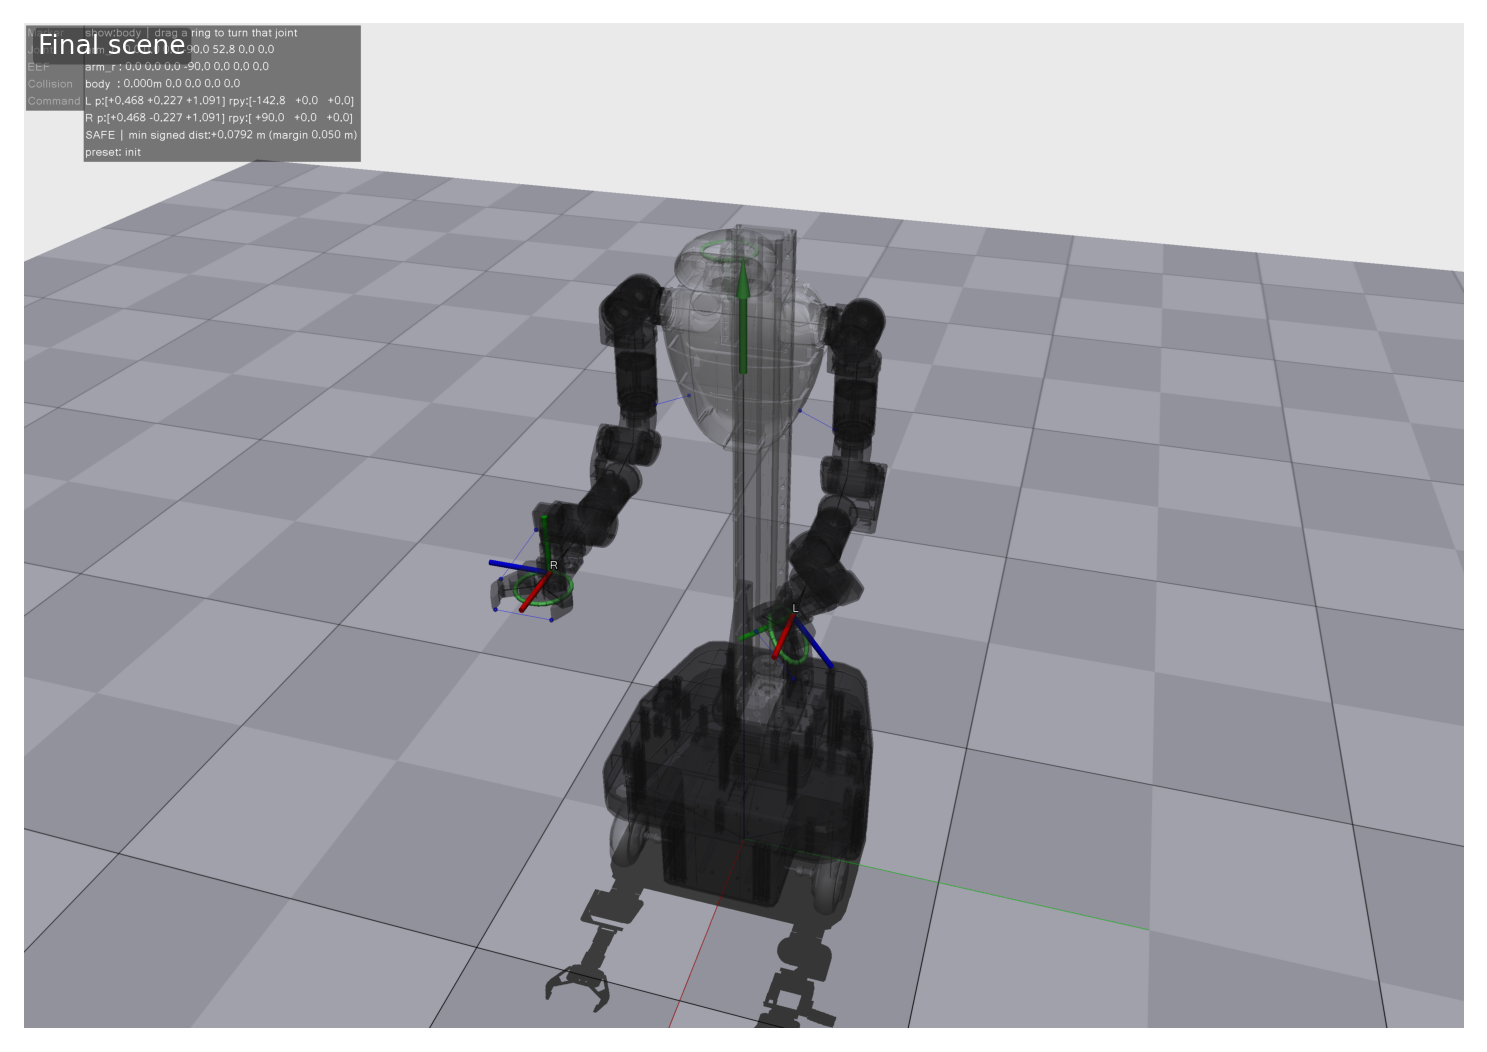

Done.


In [5]:
render_hz = 30
tmr_render = SimpleTimer(name="Joint Marker Render",Hz=render_hz,verbose=True)
tmr_render.start(); env.reset_wall_time(); env.reset_sim_time()

collision_status = None
last_command_message = ""

try:
    while env.is_viewer_alive() and ctrl_radio.isVisible():
        app.processEvents()

        if tmr_render.do_run():
            # Preset / File act once per toggle; Collision, EEF and Show are plain reads.
            command_info = handle_sg2_joint_marker_command_widget(widget=ctrl_radio,controller=controller)
            if command_info["message"]:
                last_command_message = command_info["message"]
                print("[Command]",last_command_message)

            # A drag writes that one joint's qpos; idle markers re-anchor to the joints they follow.
            controller.update()

            collision_status = None
            if command_info["check_collision"]:
                collision_status = get_sg2_self_collision_status(
                    env                  = env,
                    collision_geom_pairs = collision_geom_pairs,
                    native_backend       = native_backend,
                    safe_margin          = 0.05,
                    signed_distance_topk = 5,)
                draw_sg2_self_collision(env,collision_status)
            if command_info["show_eef"]:
                draw_sg2_wrist_frames(env)

            env.plot_global_coordinate_axes()
            env.plot_links_between_bodies(r=0.001)
            controller.draw()
            env.viewer_text_overlay("Marker",make_sg2_joint_marker_status_text(controller),loc="top left")
            env.viewer_text_overlay("Joint",make_sg2_joint_marker_overlay_text(controller),loc="top left")
            if command_info["show_eef"]:
                env.viewer_text_overlay("EEF",make_sg2_eef_overlay_text(env),loc="top left")
            env.viewer_text_overlay("Collision",make_sg2_self_collision_overlay_text(collision_status),loc="top left")
            env.viewer_text_overlay("Command",last_command_message,loc="top left")
            env.render()
            tmr_render.end()
except KeyboardInterrupt:
    print("Interrupted.")
finally:
    ctrl_radio.close()
    env.close_viewer()
    if getattr(env,"final_rgb_img",None) is not None:
        imshow(env.final_rgb_img,fig_w=6,title="Final scene",title_fs=8)
    print("Done.")